In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
pd.set_option('display.max_columns',None)

In [3]:
df=pd.read_csv(r'C:\Users\Milad\OneDrive\Desktop\python github\personal_finance_tracker_dataset.csv')
df

,date,user_id,monthly_income,monthly_expense_total,savings_rate,budget_goal,financial_scenario,credit_score,debt_to_income_ratio,loan_payment,investment_amount,subscription_services,emergency_fund,transaction_count,fraud_flag,discretionary_spending,essential_spending,income_type,rent_or_mortgage,category,cash_flow_status,financial_advice_score,financial_stress_level,actual_savings,savings_goal_met
0,2019-01-01,1584,3119.58,3212.07,0.38,3676.11,inflation,721.0,0.56,125.77,689.22,3,510.58,68,0,857.55,1910.85,Freelance,1501.65,Investments,Positive,8.3,Low,0.00,0
1,2019-01-31,1045,3262.44,3732.81,0.10,2607.17,inflation,670.0,0.42,454.19,360.34,4,1154.41,41,0,534.51,3165.20,Salary,1603.17,Investments,Positive,22.6,Low,0.00,0
2,2019-03-02,1756,2931.20,3335.58,0.15,3004.14,inflation,691.0,0.24,971.82,0.00,5,1433.02,90,0,353.67,1504.56,Freelance,1097.82,Healthcare,Positive,58.8,Low,0.00,0
3,2019-04-01,1724,3506.79,2327.59,0.17,3346.97,normal,717.0,0.16,482.76,182.06,5,227.37,94,0,594.08,1450.72,Freelance,1155.64,Groceries,Positive,74.5,Low,1179.20,0
4,2019-05-01,1600,4606.87,2182.58,0.34,2670.09,inflation,795.0,0.25,263.74,342.78,9,589.81,73,0,556.86,1000.00,Salary,1170.86,Utilities,Negative,38.7,High,2424.29,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2023-07-09,1822,3254.55,3992.02,0.17,2675.77,normal,704.0,0.30,285.16,597.74,9,466.11,81,0,408.23,2088.32,Mixed,2079.99,Healthcare,Positive,43.2,Low,0.00,0
2996,2023-08-08,1907,2752.78,5685.18,0.26,2682.99,recession,697.0,0.12,417.06,587.44,7,807.86,21,0,167.78,2445.34,Salary,832.95,Entertainment,Neutral,46.0,Low,0.00,0
2997,2023-09-07,1464,3691.10,3228.05,0.12,3893.53,normal,626.0,0.12,621.01,286.47,6,780.17,34,0,275.53,3231.56,Salary,790.68,Utilities,Neutral,40.7,Medium,463.05,0
2998,2023-10-07,1346,3133.24,4335.72,0.08,2854.72,inflation,628.0,0.42,650.23,966.60,2,712.12,92,0,373.85,2305.14,Salary,903.82,Utilities,Positive,57.1,Low,0.00,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    3000 non-null   str    
 1   user_id                 3000 non-null   int64  
 2   monthly_income          3000 non-null   float64
 3   monthly_expense_total   3000 non-null   float64
 4   savings_rate            3000 non-null   float64
 5   budget_goal             3000 non-null   float64
 6   financial_scenario      3000 non-null   str    
 7   credit_score            3000 non-null   float64
 8   debt_to_income_ratio    3000 non-null   float64
 9   loan_payment            3000 non-null   float64
 10  investment_amount       3000 non-null   float64
 11  subscription_services   3000 non-null   int64  
 12  emergency_fund          3000 non-null   float64
 13  transaction_count       3000 non-null   int64  
 14  fraud_flag              3000 non-null   int64  
 15

In [5]:
df.date=pd.to_datetime(df.date)

In [6]:
df.drop_duplicates()

,date,user_id,monthly_income,monthly_expense_total,savings_rate,budget_goal,financial_scenario,credit_score,debt_to_income_ratio,loan_payment,investment_amount,subscription_services,emergency_fund,transaction_count,fraud_flag,discretionary_spending,essential_spending,income_type,rent_or_mortgage,category,cash_flow_status,financial_advice_score,financial_stress_level,actual_savings,savings_goal_met
0,2019-01-01,1584,3119.58,3212.07,0.38,3676.11,inflation,721.0,0.56,125.77,689.22,3,510.58,68,0,857.55,1910.85,Freelance,1501.65,Investments,Positive,8.3,Low,0.00,0
1,2019-01-31,1045,3262.44,3732.81,0.10,2607.17,inflation,670.0,0.42,454.19,360.34,4,1154.41,41,0,534.51,3165.20,Salary,1603.17,Investments,Positive,22.6,Low,0.00,0
2,2019-03-02,1756,2931.20,3335.58,0.15,3004.14,inflation,691.0,0.24,971.82,0.00,5,1433.02,90,0,353.67,1504.56,Freelance,1097.82,Healthcare,Positive,58.8,Low,0.00,0
3,2019-04-01,1724,3506.79,2327.59,0.17,3346.97,normal,717.0,0.16,482.76,182.06,5,227.37,94,0,594.08,1450.72,Freelance,1155.64,Groceries,Positive,74.5,Low,1179.20,0
4,2019-05-01,1600,4606.87,2182.58,0.34,2670.09,inflation,795.0,0.25,263.74,342.78,9,589.81,73,0,556.86,1000.00,Salary,1170.86,Utilities,Negative,38.7,High,2424.29,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2023-07-09,1822,3254.55,3992.02,0.17,2675.77,normal,704.0,0.30,285.16,597.74,9,466.11,81,0,408.23,2088.32,Mixed,2079.99,Healthcare,Positive,43.2,Low,0.00,0
2996,2023-08-08,1907,2752.78,5685.18,0.26,2682.99,recession,697.0,0.12,417.06,587.44,7,807.86,21,0,167.78,2445.34,Salary,832.95,Entertainment,Neutral,46.0,Low,0.00,0
2997,2023-09-07,1464,3691.10,3228.05,0.12,3893.53,normal,626.0,0.12,621.01,286.47,6,780.17,34,0,275.53,3231.56,Salary,790.68,Utilities,Neutral,40.7,Medium,463.05,0
2998,2023-10-07,1346,3133.24,4335.72,0.08,2854.72,inflation,628.0,0.42,650.23,966.60,2,712.12,92,0,373.85,2305.14,Salary,903.82,Utilities,Positive,57.1,Low,0.00,0


In [7]:
# Which categories have the highest and lowest total monthly expenses?
df.groupby('category').monthly_expense_total.sum().sort_values(ascending=False)

category
Insurance         985392.73
Utilities         976033.03
Groceries         947379.50
Dining Out        937793.16
Healthcare        922570.97
Transportation    905593.40
Entertainment     884818.83
Education         849563.39
Investments       846820.25
Rent              779081.43
Name: monthly_expense_total, dtype: float64

In [8]:
# What is the average monthly expense for each category, and which categories have the highest and lowest averages?
df.groupby('category').monthly_expense_total.mean().sort_values(ascending=False)

category
Groceries         3075.907468
Insurance         3069.759283
Dining Out        3064.683529
Utilities         3050.103219
Entertainment     3040.614536
Healthcare        2995.360292
Transportation    2969.158689
Investments       2960.909965
Education         2939.665709
Rent              2928.877556
Name: monthly_expense_total, dtype: float64

In [9]:
# What percentage of total monthly expenses is discretionary spending?
sum(df.discretionary_spending)/sum(df.monthly_expense_total)*100

16.62894527886496

In [10]:
# What percentage of total monthly expenses is essential spending?
sum(df.essential_spending)/sum(df.monthly_expense_total)*100

73.56643001476289

In [11]:
# Does average monthly expense differ across income types?
df.groupby('income_type').monthly_expense_total.mean().sort_values(ascending=False)

income_type
Salary       3022.628333
Mixed        2989.719117
Freelance    2980.272779
Name: monthly_expense_total, dtype: float64

<Axes: xlabel='savings_rate', ylabel='Count'>

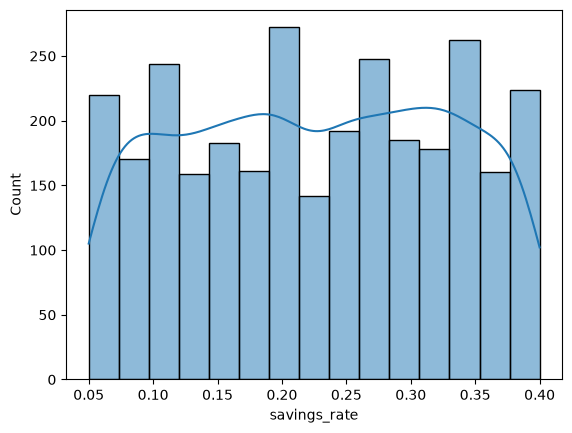

In [12]:
# What are the mean and median savings rates, and how are they distributed?
sns.histplot(df.savings_rate,kde=True)

In [13]:
# What are the mean and median savings rates, and how are they distributed?
df.savings_rate.describe()

count    3000.000000
mean        0.225897
std         0.101417
min         0.050000
25%         0.140000
50%         0.230000
75%         0.310000
max         0.400000
Name: savings_rate, dtype: float64

In [14]:
# What percentage of records indicate that the savings goal was met?
df.savings_goal_met.value_counts(normalize=True)*100

savings_goal_met
0    90.766667
1     9.233333
Name: proportion, dtype: float64

In [15]:
# Is there a relationship between savings rate and achieving the savings goal?
stats.pearsonr(df.savings_rate,df.savings_goal_met)

PearsonRResult(statistic=np.float64(-0.013323969183296331), pvalue=np.float64(0.4656884734422917))

In [16]:
# Is there a relationship between savings rate and achieving the savings goal?
stats.spearmanr(df.savings_rate,df.savings_goal_met)

SignificanceResult(statistic=np.float64(-0.012867376590785021), pvalue=np.float64(0.48111479367970944))

In [17]:
# Does average savings rate differ across financial stress levels?
df.groupby('financial_stress_level')['savings_rate'].mean().sort_values(ascending=False)

financial_stress_level
High      0.232007
Medium    0.227415
Low       0.222630
Name: savings_rate, dtype: float64

In [18]:
# Is there a relationship between monthly income and actual savings?
stats.pearsonr(df.monthly_income,df.actual_savings)

PearsonRResult(statistic=np.float64(0.7413879776931492), pvalue=np.float64(0.0))

In [19]:
# Is there a relationship between monthly income and actual savings?
stats.spearmanr(df.monthly_income,df.actual_savings)

SignificanceResult(statistic=np.float64(0.7477566922731939), pvalue=np.float64(0.0))